In [12]:
# IMPORTY
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from IPython.display import Audio
from scipy.signal import spectrogram

In [13]:
# 1.) NACTENI SINGALU
# Nacteni signalu ze souboru signal.mat
loaded_data = sio.loadmat('signal.mat')

# Extrahujeme signal z nactene struktury
signal = loaded_data['signal'].flatten()

# Prehrani signalu
Audio(data=signal, rate=fs)

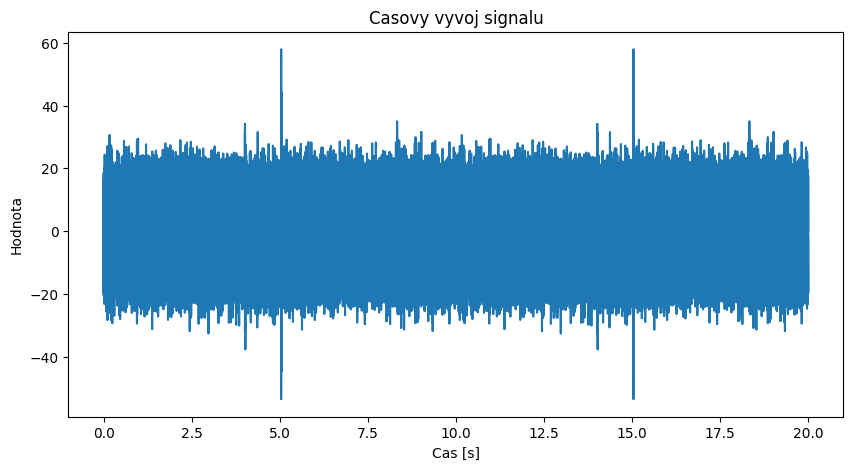

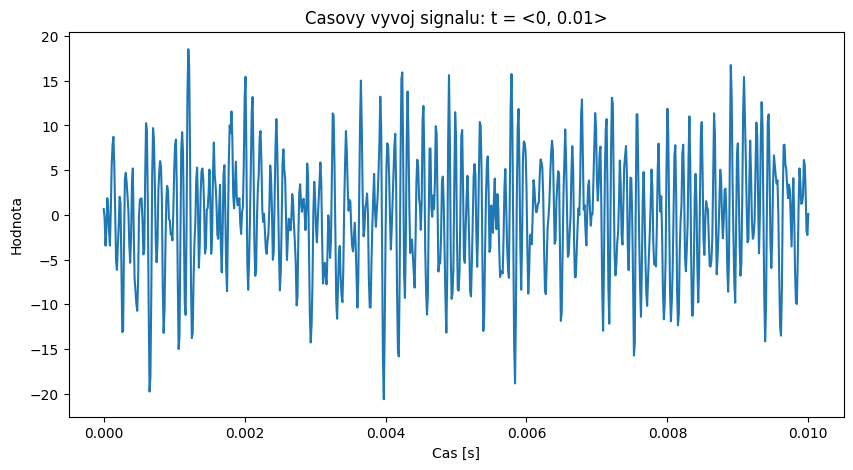

In [14]:
# 2.) CASOVY VYVOJ SIGNALU 
# vzorkovaci frekvence = 80kHz
fs = 80000  # v Hz

# Vytvoreni casove osy pro cas v sekundach
t = np.arange(len(signal)) / fs

# Zobrazeni casoveho vyvoje signalu
plt.figure(figsize=(10, 5))
plt.plot(t, signal)
plt.title('Casovy vyvoj signalu')
plt.xlabel('Cas [s]')
plt.ylabel('Hodnota')
plt.show()

# 2. podrobnejsi graf, kde t = 0-0.01
plt.figure(figsize=(10, 5))
plt.plot(t[t <= 0.01], signal[t <= 0.01])
plt.title('Casovy vyvoj signalu: t = <0, 0.01>')
plt.xlabel('Cas [s]')
plt.ylabel('Hodnota')
plt.show()

In [15]:
# 3.) URCENI CASOVYCH PARAMETRU SIGNALU
# Stredni hodnota signalu
mean_signal = np.mean(signal)

# Energie signalu
energy_signal = np.sum(signal ** 2) / fs

# Efektivni hodnotu signalu (RMS)
rms_signal = np.sqrt(np.mean(signal ** 2))

# Vypsani casovych parametru signalu
print(f'Stredni hodnota signalu: {mean_signal}')
print(f'Energie signalu: {energy_signal}')
print(f'Efektivni hodnota signalu (RMS): {rms_signal}')

Stredni hodnota signalu: -0.0003002548215313748
Energie signalu: 1025.6468732102428
Efektivni hodnota signalu (RMS): 7.1611691545802865


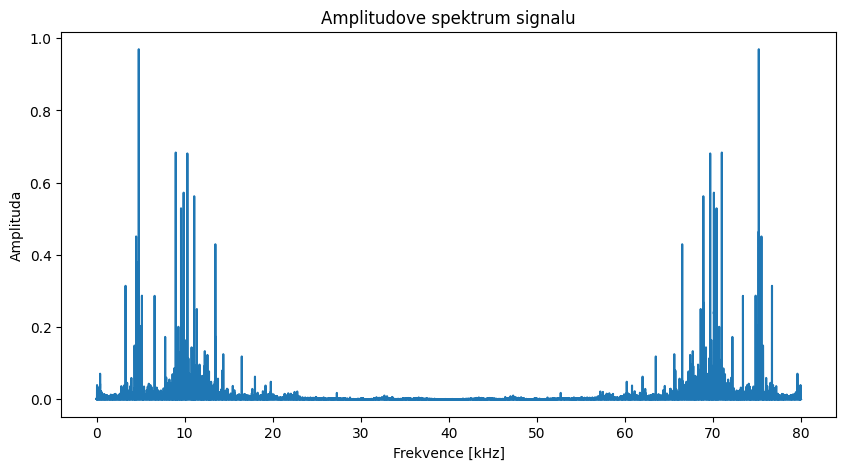

Dominantni frekvence v signalu: 4.7982 kHz


In [16]:
# 4.) URCENI FREKVENCNICH PARAMETRU SIGNALU - zobrazeni spektra:
# Vypocet diskretni Fourierovy transformace (DFT)
N = len(signal)  # Pocet vzorku
frequencies = np.arange(N) * (fs / 1000) / N  # Frekvencni osa v kHz
spectrum = np.fft.fft(signal)  # Vypocet DFT signalu
# Normalizace spektra
spectrum_normalized = np.abs(spectrum) / N

# Zobrazeni amplitudoveho spektra signalu
plt.figure(figsize=(10, 5))
plt.plot(frequencies, spectrum_normalized)
plt.title('Amplitudove spektrum signalu')
plt.xlabel('Frekvence [kHz]')
plt.ylabel('Amplituda')
plt.show()

# Urceni dominantni (maximalni) frekvence v signalu
index_max = np.argmax(spectrum_normalized)
dominant_frequency = frequencies[index_max]
print(f'Dominantni frekvence v signalu: {dominant_frequency} kHz')

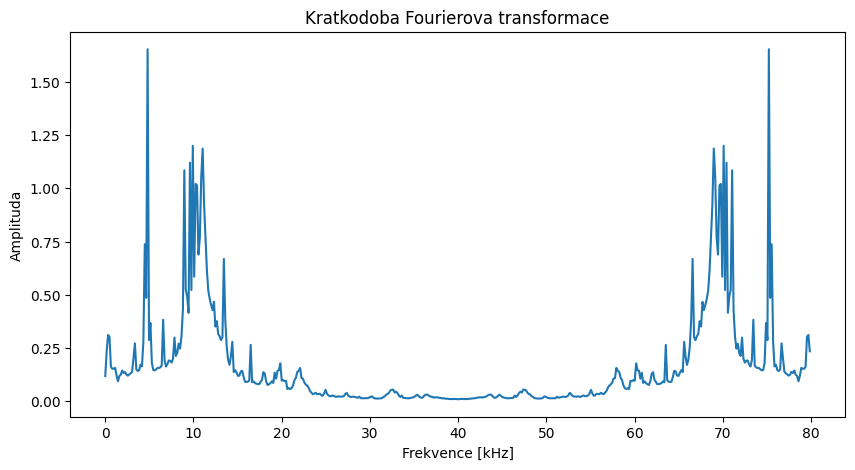

In [17]:
# 5.) METODA KRATKODOBE FOURIEROVY TRANSFORMACE (DFT/FFT)
# Pocet segmentu
num_segments = 3200  # Pocet segmentu
segment_length = N // num_segments  # Delka segmentu
overlap = 0.75  # Prekryv mezi segmenty

# Vypocet delky prekryvu
overlap_length = int(segment_length * overlap)

# Vytvoreni matic pro ukladani vysledku
spectrum_combined = np.zeros((segment_length, num_segments))
frequencies_combined = np.zeros((segment_length, num_segments))

# Kratkodoba FT na amplitudovem spektru
for i in range(num_segments):
    # Indexy pro aktualni segment
    start_index = i * (segment_length - overlap_length)
    end_index = start_index + segment_length
    
    # Vyber signalu pro aktualni segment
    segment_signal = signal[start_index:end_index]
    
    # Vypocet frekvencni osy v kHz
    frequencies_segment = np.arange(segment_length) * (fs / 1000) / segment_length
    
    # Vypocet DFT signalu pro aktualni segment
    spectrum = np.fft.fft(segment_signal)
    
    # Normalizace spektra
    spectrum_normalized = np.abs(spectrum) / segment_length
    
    # Ulozeni spektra do spolecne matice
    spectrum_combined[:, i] = spectrum_normalized
    frequencies_combined[:, i] = frequencies_segment

# Prumerovani spekter z jednotlivych segmentu
average_spectrum = np.mean(spectrum_combined, axis=1)

# Vykresleni prumerneho amplitudoveho spektra
plt.figure(figsize=(10, 5))
plt.plot(frequencies_combined[:, 0], average_spectrum)
plt.title('Kratkodoba Fourierova transformace')
plt.xlabel('Frekvence [kHz]')
plt.ylabel('Amplituda')
plt.show()

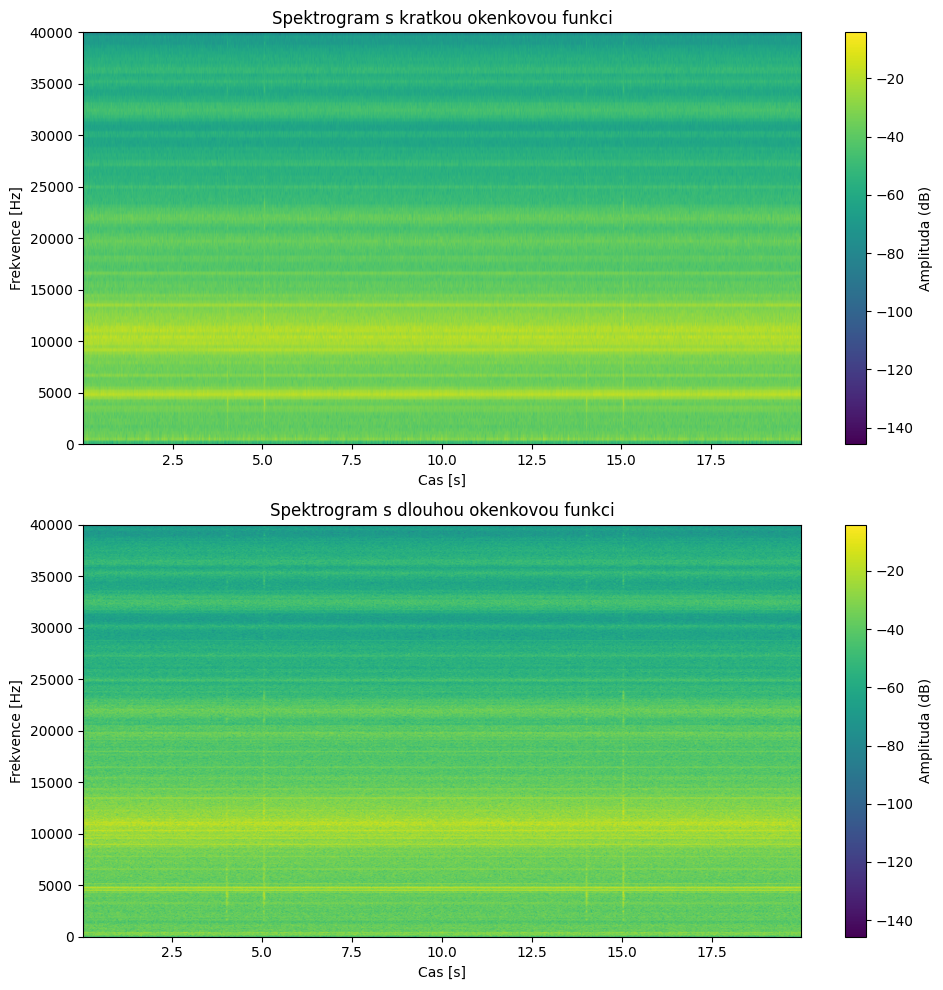

In [18]:
# 6.) SPEKTROGRAMY PRO KRATKOU A DLOUHOU OKENKOVOU FUNKCI
# Kratka okenkova funkce (napr. 256 vzorku)
window_length_s = 256
overlap_s = 0.5
nfft_short = 256  # Pocet vzorku DFT - rozliseni frekvenci
f_short, t_stft_short, s_short = spectrogram(signal, fs, nperseg=window_length_s, 
                                             noverlap=int(window_length_s * overlap_s), 
                                             nfft=nfft_short)

# Dlouha okenkova funkce (napr. 4096 vzorku)
window_length_l = 4096
overlap_l = 0.5
nfft_long = 8192  # Pocet vzorku DFT pro dlouhe okno
f_long, t_stft_long, s_long = spectrogram(signal, fs, nperseg=window_length_l, 
                                          noverlap=int(window_length_l * overlap_l), 
                                          nfft=nfft_long)

# Zobrazeni spektrogramu
plt.figure(figsize=(10, 10))

plt.subplot(2, 1, 1)
plt.imshow(10 * np.log10(np.abs(s_short)), aspect='auto', origin='lower', 
           extent=[t_stft_short.min(), t_stft_short.max(), f_short.min(), f_short.max()])
plt.title('Spektrogram s kratkou okenkovou funkci')
plt.xlabel('Cas [s]')
plt.ylabel('Frekvence [Hz]')
plt.colorbar(label='Amplituda (dB)')
plt.clim(10 * np.log10(np.abs(s_short)).min(), 10 * np.log10(np.abs(s_long)).max())

plt.subplot(2, 1, 2)
plt.imshow(10 * np.log10(np.abs(s_long)), aspect='auto', origin='lower', 
           extent=[t_stft_long.min(), t_stft_long.max(), f_long.min(), f_long.max()])
plt.title('Spektrogram s dlouhou okenkovou funkci')
plt.xlabel('Cas [s]')
plt.ylabel('Frekvence [Hz]')
plt.colorbar(label='Amplituda (dB)')
plt.clim(10 * np.log10(np.abs(s_short)).min(), 10 * np.log10(np.abs(s_long)).max())

plt.tight_layout()
plt.show()